# Name: Golam Kibria
## Id  : 011201369

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

In [17]:
df=pd.read_csv('Merge_data_v5.csv')

In [18]:
df.head()

,Unnamed: 0,CO2CosIRValue_stat_3,CO2CosIRValue_tm_dom_9,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_5,CO2CosIRValue_xf_jerk_9,CO2CosIRValue_xt_jerk_9,CO2CosIRValue_tm_dom_2,CO2CosIRValue_tm_dom_16,CO2CosIRValue_xf_jerk_2,...,CO2CosIRValue_xf_jerk_14,CO2CosIRValue_tm_dom_15,CO2CosIRValue_xf_jerk_15,COValue_stat_7,COValue_stat_3,COValue_tm_dom_9,COValue_stat_9,COValue_xt_jerk_1,COValue_tm_dom_17,total_count
0,0,5.494463,1.182329e+08,1.298992e+06,2.861258,77540.839509,883.408743,1.164276,120.839121,3.013913,...,9.326055,120.839121,17.929601,1.260655,2.219376,1.506572e+08,1.655758e+06,10.506700,82.449622,12.0
1,1,4.854607,1.106247e+08,1.215007e+06,3.798223,42434.593364,473.110720,0.283703,114.836023,4.096936,...,13.772698,114.836023,14.457048,4.673625,6.956150,2.044977e+08,2.248982e+06,8.142400,198.747468,2.0
2,2,3.155584,1.210164e+08,1.330320e+06,1.556766,23413.255832,262.265654,1.790157,53.435480,0.658388,...,2.720878,64.379547,4.244554,1.712750,3.116128,1.911371e+08,2.099543e+06,7.990829,106.576297,8.0
3,3,1.562510,1.243438e+08,1.366368e+06,4.049524,37747.290022,420.126594,1.619635,66.845466,0.101616,...,3.876383,12.118217,1.374782,0.992575,1.947794,1.916808e+08,2.106550e+06,5.621770,75.397925,9.0
4,4,2.315781,1.850559e+08,2.033435e+06,4.135966,13561.770508,150.776617,1.768394,171.191384,0.844150,...,3.720942,30.141195,3.582027,1.418210,2.241431,2.330677e+08,2.560863e+06,9.395000,101.438317,10.0


In [19]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [20]:
#df['move_type'] = df['total_count'].apply(lambda x: 1 if x > 10.0 else 0)
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [21]:
df['move_type'].unique()

array([2, 1, 0])

In [22]:
df.corr()

,Unnamed: 0,CO2CosIRValue_stat_3,CO2CosIRValue_tm_dom_9,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_5,CO2CosIRValue_xf_jerk_9,CO2CosIRValue_xt_jerk_9,CO2CosIRValue_tm_dom_2,CO2CosIRValue_tm_dom_16,CO2CosIRValue_xf_jerk_2,...,CO2CosIRValue_tm_dom_15,CO2CosIRValue_xf_jerk_15,COValue_stat_7,COValue_stat_3,COValue_tm_dom_9,COValue_stat_9,COValue_xt_jerk_1,COValue_tm_dom_17,total_count,move_type
Unnamed: 0,1.000000,0.119531,0.088431,0.088423,0.020998,0.166309,0.172347,0.170268,0.190867,0.142590,...,0.146230,0.173981,0.085511,0.103666,0.081442,0.081440,0.132284,0.143365,0.307860,0.401437
CO2CosIRValue_stat_3,0.119531,1.000000,0.462213,0.462370,0.408228,0.718091,0.671528,0.535981,0.789230,0.683895,...,0.847161,0.731575,0.614698,0.632553,0.412413,0.412529,0.572640,0.594460,0.281678,0.277435
CO2CosIRValue_tm_dom_9,0.088431,0.462213,1.000000,1.000000,0.188404,0.326431,0.282592,0.218681,0.368942,0.318261,...,0.446245,0.358596,0.421800,0.388932,0.750173,0.749923,0.402531,0.364404,0.334933,0.202016
CO2CosIRValue_stat_9,0.088423,0.462370,1.000000,1.000000,0.188415,0.326535,0.282685,0.218677,0.369053,0.318336,...,0.446321,0.358664,0.422005,0.389141,0.750344,0.750094,0.402613,0.364541,0.334874,0.202012
CO2CosIRValue_xt_jerk_5,0.020998,0.408228,0.188404,0.188415,1.000000,0.212828,0.153780,0.163494,0.278928,0.302350,...,0.385774,0.339032,0.142131,0.145505,0.132079,0.132073,0.143254,0.117741,0.127393,0.092207
CO2CosIRValue_xf_jerk_9,0.166309,0.718091,0.326431,0.326535,0.212828,1.000000,0.992439,0.649053,0.724174,0.651537,...,0.672926,0.681651,0.501772,0.527096,0.311419,0.311544,0.529065,0.489840,0.256375,0.267923
CO2CosIRValue_xt_jerk_9,0.172347,0.671528,0.282592,0.282685,0.153780,0.992439,1.000000,0.663507,0.702790,0.624361,...,0.634461,0.656497,0.464535,0.496324,0.273826,0.273949,0.512766,0.476041,0.250003,0.271844
CO2CosIRValue_tm_dom_2,0.170268,0.535981,0.218681,0.218677,0.163494,0.649053,0.663507,1.000000,0.566117,0.469336,...,0.493647,0.484651,0.299731,0.326930,0.193570,0.193602,0.375646,0.388426,0.252805,0.275062
CO2CosIRValue_tm_dom_16,0.190867,0.789230,0.368942,0.369053,0.278928,0.724174,0.702790,0.566117,1.000000,0.631970,...,0.775292,0.733342,0.486190,0.508963,0.283340,0.283480,0.476211,0.506768,0.323957,0.340185
CO2CosIRValue_xf_jerk_2,0.142590,0.683895,0.318261,0.318336,0.302350,0.651537,0.624361,0.469336,0.631970,1.000000,...,0.626032,0.594554,0.435488,0.462943,0.261650,0.261740,0.479035,0.472701,0.253782,0.287153


In [23]:
del df['Unnamed: 0']
del df['CO2CosIRValue_xf_jerk_9']

In [24]:
del df['CO2CosIRValue_stat_9']

In [25]:
del df['CO2CosIRValue_xt_jerk_5']

In [26]:
del df['COValue_stat_9']

In [27]:
del df['CO2CosIRValue_stat_3']

In [28]:
del df['COValue_tm_dom_9']

In [29]:
del df['CO2CosIRValue_tm_dom_14']

In [30]:
del df['CO2CosIRValue_tm_dom_15']

In [31]:
del df['COValue_stat_3']

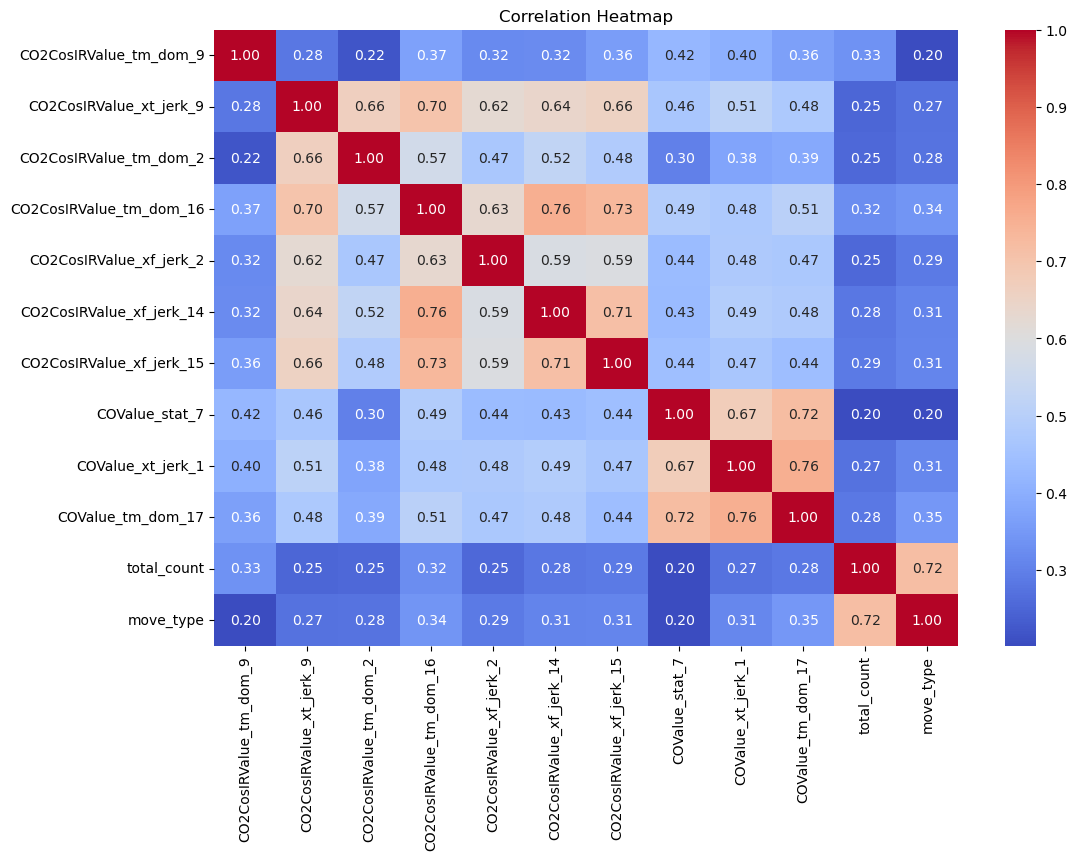

In [32]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [33]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [34]:
y

0       2
1       1
2       2
3       2
4       2
       ..
1933    0
1934    0
1935    0
1936    0
1937    0
Name: move_type, Length: 1938, dtype: int64

In [54]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=877)

# Features selection:

In [122]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

# Create the RFE model and select 8 features
rfe = RFE(model, n_features_to_select=8)

# Fit the RFE model and transform the data
X_train_rfe = rfe.fit_transform(X_train, y_train)
X_test_rfe = rfe.transform(X_test)

# Get the ranking and support arrays
ranking = rfe.ranking_
support = rfe.support_

# Get the names of the top 10 features
selected_features = [feature_names[i] for i, (is_selected) in enumerate(support) if is_selected]

print("Top 8 Selected Features:")
for feature_name in selected_features:
    print(feature_name)


Top 8 Selected Features:
CO2CosIRValue_tm_dom_9
CO2CosIRValue_stat_9
CO2CosIRValue_xf_jerk_9
CO2CosIRValue_xt_jerk_9
CO2CosIRValue_tm_dom_16
CO2CosIRValue_tm_dom_14
COValue_stat_9
COValue_tm_dom_17


In [103]:
keep_list=[
'CO2CosIRValue_tm_dom_9',
'CO2CosIRValue_xf_jerk_9',
'CO2CosIRValue_xt_jerk_9',
'CO2CosIRValue_tm_dom_16',
'COValue_stat_9',
'COValue_tm_dom_17'
]

In [104]:
X=X[keep_list].copy()

In [55]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [125]:
min_max_scaler = MinMaxScaler()
X = min_max_scaler.fit_transform(X)

In [56]:
standard_scaler = StandardScaler()
X = standard_scaler.fit_transform(X)

In [126]:
X.shape

(1938, 19)

# Random forest

In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

clf = RandomForestClassifier(n_estimators=200,max_depth=5)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.7360824742268042


In [67]:
y_pred_train = clf.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.7370956641431521


In [46]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
xgb_model = xgb.XGBClassifier(objective='multi:softmax', num_class=len(set(y)))

param_grid = {
    'learning_rate': [0.01, 0.1, 0.2, 0.001, 0.0001],
    'max_depth': [3, 4, 5],
    'n_estimators': [50, 100, 200],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, scoring='accuracy', cv=5)

# Perform the grid search on the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and the best model
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

# Make predictions on the test set using the best model
y_pred = best_model.predict(X_test)

# Evaluate the performance of the best model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("Best Parameters:", best_params)
print(f"Accuracy with Best Model: {accuracy:.2f}")
print("Classification Report:\n", report)

Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.0001, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Accuracy with Best Model: 0.70
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.81      0.82       113
           1       0.64      0.32      0.42       130
           2       0.66      0.85      0.74       242

    accuracy                           0.70       485
   macro avg       0.71      0.66      0.66       485
weighted avg       0.69      0.70      0.68       485



In [68]:
model=xgb.XGBClassifier(objective='multi:softmax',colsample_bytree=0.8,learning_rate=0.0001,max_depth=5,n_estimators=100,subsample=0.8, num_class=len(set(y)))
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

In [69]:
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.75
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.84      0.88       112
           1       0.63      0.30      0.41       113
           2       0.72      0.91      0.80       260

    accuracy                           0.75       485
   macro avg       0.76      0.68      0.70       485
weighted avg       0.75      0.75      0.73       485



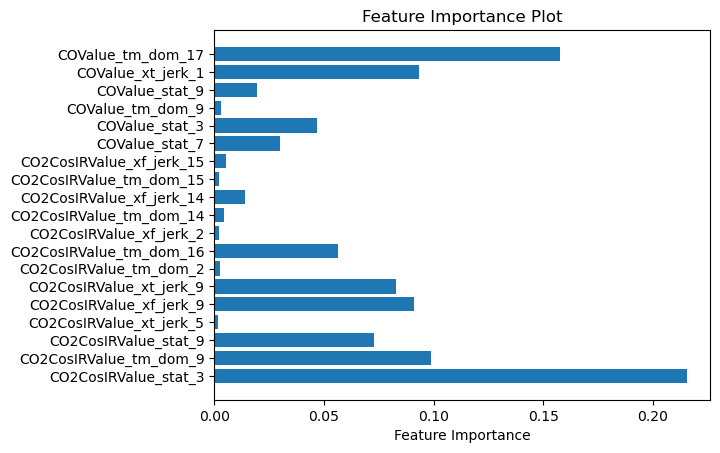

In [148]:
# Visualize feature importance
feature_importance = clf.feature_importances_

plt.barh(feature_names, feature_importance)
plt.xlabel('Feature Importance')
plt.title('Feature Importance Plot')
plt.show()

# SVM

In [ ]:
from sklearn.svm import SVC
svm_classifier = SVC(kernel='linear', C=0.9)
svm_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = svm_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)

# KNN

In [63]:
from sklearn.neighbors import KNeighborsClassifier
knn_classifier = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = knn_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)

Accuracy: 0.48195876288659795
Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.74      0.65        88
           1       0.43      0.57      0.49       143
           2       0.47      0.25      0.33       157

    accuracy                           0.48       388
   macro avg       0.49      0.52      0.49       388
weighted avg       0.48      0.48      0.46       388



# Logistic 

In [80]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
classifier = LogisticRegression(multi_class='ovr', max_iter=1000)

# Train the classifier
classifier.fit(X_train, y_train)

# Make predictions
y_pred = classifier.predict(X_test)

# Evaluate the accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 0.40824742268041236


In [ ]:
df.column